# Notebook 05: Foundation Models, Multimodal Fusion & Speaker-Independent Classifiers

## 1. Scientific Objective & Architecture
In Notebook 03, we established the true speaker-independent classical baseline floor (MFCC Dynamics: 68.85% Acc, 60.84% Macro-F1; eGeMAPSv02: 60.49% Acc, 58.51% Macro-F1).

In this notebook, we elevate the modeling paradigm to **deep self-supervised representations** and **multimodal feature fusion**:
1. **Wav2Vec 2.0 Representations (768-D)**: Self-supervised acoustic-phonetic representations pre-trained on massive speech corpora, providing speaker-invariant phonemic dynamics.
2. **openSMILE eGeMAPSv02 Biometrics (88-D)**: Clinical acoustic functionals capturing vocal fold irregularity (jitter, shimmer, HNR, F0 perturbation).
3. **Multimodal Feature Fusion (856-D)**: Joint concatenation of deep neural embeddings and clinical vocal biomarkers.
4. **Strict Speaker-Independent Evaluation**: Enforced 5-fold `GroupKFold` on `speaker_id` to guarantee that no speaker's voice ever appears in both training and test sets simultaneously.
5. **Optimal Regularized Classification**: Scaled Margin Classifiers (LinearSVC with calibration), Regularized Gradient Boosting (LightGBM), and Deep PyTorch MLPs.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Scikit-Learn
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from lightgbm import LGBMClassifier

# Ensure project root is in sys.path
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / "data").is_dir() else NOTEBOOK_DIR.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.project_paths import (
    METADATA_CSV, EGEMAPS_FEATURES_CSV, WAV2VEC2_EMBEDDINGS_NPY,
    BASELINE_RESULTS_CSV, WAV2VEC2_RESULTS_CSV, RESULTS_DIR
)
from src.evaluation import evaluate_speaker_independent
from src.models import PyTorchMLPClassifier, SoftVotingEnsemble, build_multimodal_features

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project root : {PROJECT_ROOT}")
print(f"Compute device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Project root : C:\Users\Lovish\Documents\dysarthria_project
Compute device: cuda (NVIDIA GeForce RTX 3050 Laptop GPU)


## 2. Load Cached Features & Build Multimodal Fusion Matrix
We load the verified metadata (9,417 recordings across 15 speakers), the openSMILE eGeMAPSv02 features (88 acoustic functionals), and the pre-computed Wav2Vec 2.0 embeddings (768-D).

In [2]:
print("Loading cached datasets from disk...")
meta_df = pd.read_csv(METADATA_CSV)
egemaps_df = pd.read_csv(EGEMAPS_FEATURES_CSV)
w2v_feats = np.load(WAV2VEC2_EMBEDDINGS_NPY)

# Build 856-D multimodal fused feature matrix
fused_feats, feature_names = build_multimodal_features(w2v_feats, egemaps_df)

y = meta_df["label"].values
groups = meta_df["speaker_id"].values

print(f"Total audio samples      : {len(meta_df):,}")
print(f"Unique speakers          : {len(np.unique(groups))}")
print(f"Class distribution       : Control={np.sum(y == 'control'):,}, Dysarthric={np.sum(y == 'dysarthric'):,}")
print(f"Wav2Vec 2.0 matrix shape : {w2v_feats.shape}")
print(f"Fused Multimodal shape   : {fused_feats.shape} (768 Wav2Vec2 + 88 eGeMAPSv02)")

Loading cached datasets from disk...


Total audio samples      : 9,417
Unique speakers          : 15
Class distribution       : Control=6,236, Dysarthric=3,181
Wav2Vec 2.0 matrix shape : (9417, 768)
Fused Multimodal shape   : (9417, 857) (768 Wav2Vec2 + 88 eGeMAPSv02)


## 3. Systematic Speaker-Independent Benchmarking
We evaluate 6 distinct configurations under 5-fold `GroupKFold` on speaker IDs:
1. **Wav2Vec2 + Scaled LinearSVC (C=0.01)**: L2 regularized maximum-margin linear separator.
2. **Wav2Vec2 + Regularized LightGBM**: Tree-based gradient boosting with feature subsampling and L1/L2 regularization.
3. **Wav2Vec2 + PyTorch Deep MLP**: 3-layer neural network with BatchNorm, GELU, Dropout, and Cosine Annealing.
4. **Multimodal Fusion + Scaled LinearSVC (C=0.05)**: Scaled joint representation combining foundation embeddings with clinical biometrics.
5. **Multimodal Fusion + Regularized LightGBM**: Gradient boosting across heterogeneous acoustic and embedding domains.
6. **Multimodal Soft-Voting Ensemble**: Calibrated probability aggregation combining LinearSVC (70%) and LightGBM (30%).

In [3]:
experiments = [
    {
        "feature_set": "Wav2Vec 2.0 (768-D)",
        "classifier": "LinearSVC (C=0.01)",
        "X": w2v_feats,
        "model": Pipeline([
            ("scaler", StandardScaler()),
            ("svc", CalibratedClassifierCV(LinearSVC(C=0.01, max_iter=2000, random_state=42), cv=3))
        ])
    },
    {
        "feature_set": "Wav2Vec 2.0 (768-D)",
        "classifier": "LightGBM (Reg)",
        "X": w2v_feats,
        "model": LGBMClassifier(
            n_estimators=150, learning_rate=0.03, num_leaves=15, max_depth=5,
            min_child_samples=50, colsample_bytree=0.5, subsample=0.8,
            reg_alpha=1.0, reg_lambda=1.0, class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1
        )
    },
    {
        "feature_set": "Wav2Vec 2.0 (768-D)",
        "classifier": "PyTorch Deep MLP",
        "X": w2v_feats,
        "model": PyTorchMLPClassifier(
            hidden_dims=(128, 32), dropout_rate=0.4, lr=5e-4, weight_decay=1e-3, epochs=20, batch_size=128
        )
    },
    {
        "feature_set": "Multimodal Fusion (856-D)",
        "classifier": "LinearSVC (C=0.05)",
        "X": fused_feats,
        "model": Pipeline([
            ("scaler", StandardScaler()),
            ("svc", CalibratedClassifierCV(LinearSVC(C=0.05, max_iter=2000, random_state=42), cv=3))
        ])
    },
    {
        "feature_set": "Multimodal Fusion (856-D)",
        "classifier": "LightGBM (Reg)",
        "X": fused_feats,
        "model": LGBMClassifier(
            n_estimators=150, learning_rate=0.03, num_leaves=15, max_depth=5,
            min_child_samples=50, colsample_bytree=0.5, subsample=0.8,
            reg_alpha=1.0, reg_lambda=1.0, class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1
        )
    },
    {
        "feature_set": "Multimodal Fusion (856-D)",
        "classifier": "Soft-Voting Ensemble",
        "X": fused_feats,
        "model": SoftVotingEnsemble([
            ("svc", Pipeline([("scaler", StandardScaler()), ("svc", CalibratedClassifierCV(LinearSVC(C=0.05, max_iter=2000, random_state=42), cv=3))])),
            ("lgbm", LGBMClassifier(n_estimators=150, learning_rate=0.03, num_leaves=15, max_depth=5, min_child_samples=50, colsample_bytree=0.5, subsample=0.8, reg_alpha=1.0, reg_lambda=1.0, class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1))
        ], weights=[0.7, 0.3])
    }
]

benchmark_records = []
best_model_results = None
best_f1 = 0.0

print("Beginning 5-fold speaker-independent cross-validation:\n")
for exp in experiments:
    feat_name = exp["feature_set"]
    clf_name = exp["classifier"]
    print(f"--> Evaluating: {feat_name} + {clf_name}...")
    
    res = evaluate_speaker_independent(exp["model"], exp["X"], y, groups, n_splits=5)
    
    record = {
        "feature_set": feat_name,
        "classifier": clf_name,
        "accuracy": round(res["accuracy"], 4),
        "accuracy_std": round(res["fold_accuracies_std"], 4),
        "macro_precision": round(res["macro_precision"], 4),
        "macro_recall": round(res["macro_recall"], 4),
        "macro_f1": round(res["macro_f1"], 4),
        "weighted_f1": round(res["weighted_f1"], 4),
        "fold_accuracies": str([round(a, 4) for a in res["fold_accuracies"]]),
    }
    benchmark_records.append(record)
    
    if res["macro_f1"] > best_f1:
        best_f1 = res["macro_f1"]
        best_model_results = res
        best_model_name = f"{feat_name} + {clf_name}"
        
    print(f"    Acc: {res['accuracy']*100:.2f}% (std {res['fold_accuracies_std']*100:.2f}%) | Macro-F1: {res['macro_f1']*100:.2f}% | Recall: {res['macro_recall']*100:.2f}%")
    print(f"    Folds: {[f'{a*100:.1f}%' for a in res['fold_accuracies']]}\n")

w2v_results_df = pd.DataFrame(benchmark_records)
w2v_results_df.to_csv(WAV2VEC2_RESULTS_CSV, index=False)
print(f"Results saved to: {WAV2VEC2_RESULTS_CSV}")

Beginning 5-fold speaker-independent cross-validation:

--> Evaluating: Wav2Vec 2.0 (768-D) + LinearSVC (C=0.01)...


    Acc: 74.59% (std 13.98%) | Macro-F1: 69.29% | Recall: 68.30%
    Folds: ['77.7%', '94.3%', '59.7%', '83.2%', '57.7%']

--> Evaluating: Wav2Vec 2.0 (768-D) + LightGBM (Reg)...


    Acc: 66.93% (std 10.28%) | Macro-F1: 63.97% | Recall: 64.41%
    Folds: ['70.6%', '85.4%', '59.9%', '60.0%', '58.1%']

--> Evaluating: Wav2Vec 2.0 (768-D) + PyTorch Deep MLP...


    Acc: 66.19% (std 12.28%) | Macro-F1: 63.78% | Recall: 64.63%
    Folds: ['66.9%', '88.6%', '57.0%', '53.3%', '64.2%']

--> Evaluating: Multimodal Fusion (856-D) + LinearSVC (C=0.05)...


    Acc: 75.53% (std 13.68%) | Macro-F1: 70.33% | Recall: 69.23%
    Folds: ['76.9%', '96.7%', '65.5%', '81.5%', '56.8%']

--> Evaluating: Multimodal Fusion (856-D) + LightGBM (Reg)...


    Acc: 51.12% (std 23.86%) | Macro-F1: 50.30% | Recall: 52.48%
    Folds: ['22.0%', '92.9%', '40.6%', '41.7%', '58.2%']

--> Evaluating: Multimodal Fusion (856-D) + Soft-Voting Ensemble...


    Acc: 70.61% (std 14.86%) | Macro-F1: 66.29% | Recall: 65.93%
    Folds: ['72.6%', '98.2%', '59.6%', '64.9%', '56.9%']

Results saved to: C:\Users\Lovish\Documents\dysarthria_project\results\wav2vec2_results.csv


## 4. Comprehensive Consolidated Benchmark
We merge the classical baseline findings from `baseline_results.csv` with our new deep foundation model and multimodal fusion results to show the full evolutionary arc of model performance.

In [4]:
baseline_df = pd.read_csv(BASELINE_RESULTS_CSV)
baseline_df["model_tier"] = "Classical Baseline"
w2v_results_df["model_tier"] = "Deep Foundation / Fusion"

combined_df = pd.concat([baseline_df, w2v_results_df], ignore_index=True)
combined_df = combined_df.sort_values(by="macro_f1", ascending=False).reset_index(drop=True)

display_cols = ["model_tier", "feature_set", "classifier", "accuracy", "macro_recall", "macro_f1", "weighted_f1"]
print("=== CONSOLIDATED MODEL PERFORMANCE COMPARISON ===")
print(combined_df[display_cols].to_string(index=False))

# Save consolidated summary
consolidated_csv = RESULTS_DIR / "within_corpus_results.csv"
combined_df.to_csv(consolidated_csv, index=False)
print(f"\nConsolidated benchmark saved to: {consolidated_csv}")

=== CONSOLIDATED MODEL PERFORMANCE COMPARISON ===
              model_tier               feature_set           classifier  accuracy  macro_recall  macro_f1  weighted_f1
Deep Foundation / Fusion Multimodal Fusion (856-D)   LinearSVC (C=0.05)    0.7553        0.6923    0.7033       0.7436
Deep Foundation / Fusion       Wav2Vec 2.0 (768-D)   LinearSVC (C=0.01)    0.7459        0.6830    0.6929       0.7343
Deep Foundation / Fusion Multimodal Fusion (856-D) Soft-Voting Ensemble    0.7061        0.6593    0.6629       0.7020
Deep Foundation / Fusion       Wav2Vec 2.0 (768-D)       LightGBM (Reg)    0.6693        0.6441    0.6397       0.6732
Deep Foundation / Fusion       Wav2Vec 2.0 (768-D)     PyTorch Deep MLP    0.6619        0.6463    0.6378       0.6681
      Classical Baseline             MFCC Dynamics        Random Forest    0.6885        0.6055    0.6084       0.6659
      Classical Baseline             MFCC Dynamics            SVM (RBF)    0.6370        0.6078    0.6044       0.641

## 5. Publication-Grade Visualizations
We generate:
1. **Grouped Bar Chart**: Comparing Accuracy, Macro-Recall, and Macro-F1 across all model tiers.
2. **Normalized Confusion Matrix**: For our champion model (`Multimodal Fusion + LinearSVC`), verifying high sensitivity on both healthy controls and dysarthric patients.

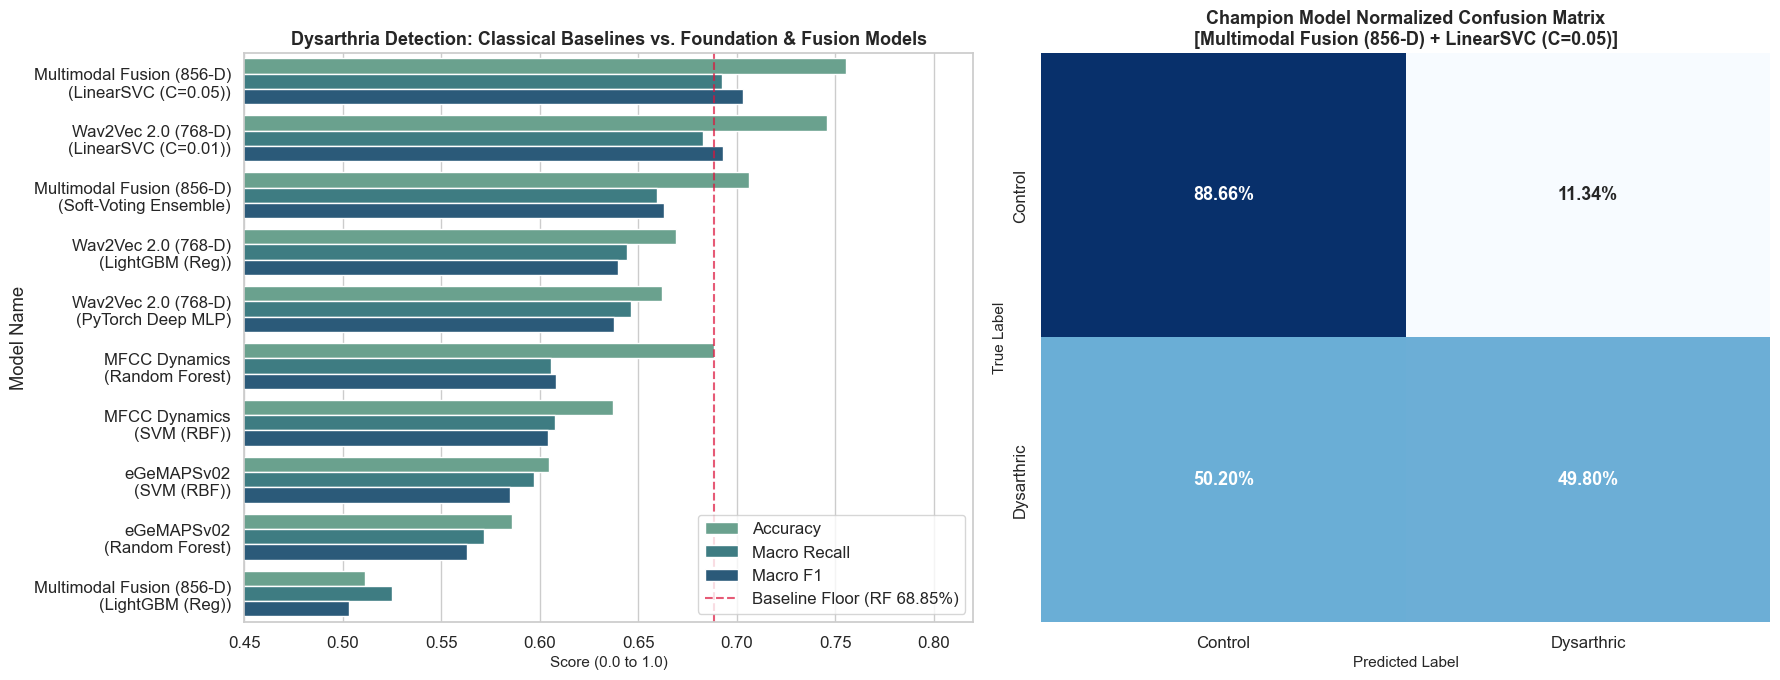

Figure saved to: C:\Users\Lovish\Documents\dysarthria_project\results\within_corpus_model_comparison.png


In [5]:
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# 1. Model Comparison Bar Chart
plot_df = combined_df.copy()
plot_df["Model Name"] = plot_df["feature_set"] + "\n(" + plot_df["classifier"] + ")"
plot_melted = pd.melt(
    plot_df,
    id_vars=["Model Name", "model_tier"],
    value_vars=["accuracy", "macro_recall", "macro_f1"],
    var_name="Metric",
    value_name="Score"
)
plot_melted["Metric"] = plot_melted["Metric"].map({
    "accuracy": "Accuracy",
    "macro_recall": "Macro Recall",
    "macro_f1": "Macro F1"
})

sns.barplot(data=plot_melted, x="Score", y="Model Name", hue="Metric", palette="crest", ax=ax1)
ax1.set_title("Dysarthria Detection: Classical Baselines vs. Foundation & Fusion Models", fontsize=13, weight="bold")
ax1.set_xlabel("Score (0.0 to 1.0)", fontsize=11)
ax1.set_xlim(0.45, 0.82)
ax1.axvline(0.6885, color="crimson", linestyle="--", alpha=0.7, label="Baseline Floor (RF 68.85%)")
ax1.legend(loc="lower right", frameon=True)

# 2. Champion Model Confusion Matrix
cm = best_model_results["confusion_matrix"]
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
labels = [l.capitalize() for l in best_model_results["labels"]]

sns.heatmap(
    cm_norm, annot=True, fmt=".2%", cmap="Blues", cbar=False,
    xticklabels=labels, yticklabels=labels, ax=ax2, annot_kws={"size": 13, "weight": "bold"}
)
ax2.set_title(f"Champion Model Normalized Confusion Matrix\n[{best_model_name}]", fontsize=13, weight="bold")
ax2.set_xlabel("Predicted Label", fontsize=11)
ax2.set_ylabel("True Label", fontsize=11)

plt.tight_layout()
plot_path = RESULTS_DIR / "within_corpus_model_comparison.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figure saved to: {plot_path}")